# Lab 10 — Extractive Question Answering

Mạc Văn Tường — 23001951 — MAT3561E 4. SQuAD 1.1, baseline lexical overlap và ALBERT với start/end head.

In [1]:
from pathlib import Path
import os, sys, json
root=Path.cwd().resolve()
if (root/'qa_model.py').exists():
    root=root.parent
assert (root/'Lab10').exists(), 'Run from repository root or Lab10'
lab_dir=root/'Lab10'
sys.path.insert(0,str(lab_dir))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from qa_model import (CONFIG, DEVICE, CHECKPOINT_DIR, seed_everything, load_splits,
    split_signature, get_tokenizer, encode_examples, align_span, normalize_answer,
    score_answer, example_score, evaluate_answers, KeywordBaseline, word_terms,
    sentence_ranges, train_or_restore, get_model, predict_examples, atomic_json)
seed_everything()
splits=load_splits(1000,200,200)
tokenizer=get_tokenizer()
print('Split sizes:',{k:len(v) for k,v in splits.items()})
print('Config:',CONFIG,'| device:',DEVICE)
print('Source SHA256:',split_signature(splits)['source_sha256'])

D:\Project\NLP-2025\NLP-Labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Split sizes: {'train': 1000, 'validation': 200, 'test': 200}
Config: {'model': 'albert/albert-base-v2', 'revision': '8e2f239c5f8a2c0f253781ca60135db913e5c80c', 'seed': 42, 'batch_size': 4, 'epochs': 2, 'learning_rate': 3e-05, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'stride': 32, 'max_question_tokens': 64, 'max_answer_tokens': 64} | device: cpu
Source SHA256: {'train': '3527663986b8295af4f7fcdff1ba1ff3f72d07d61a20f487cb238a6ef92fd955', 'dev': '95aa6a52d5d6a735563366753ca50492a658031da74f301ac5238b03966972c9'}


## 3–5. Dataset và prediction heads

In [2]:
inspection=[]
for name,rows in splits.items():
    inspection.append(dict(split=name,questions=len(rows),articles=len({r['title'] for r in rows}),
        contexts=len({r['context'] for r in rows}),mean_context_words=np.mean([len(r['context'].split()) for r in rows]),
        mean_answer_words=np.mean([len(r['answers'][0]['text'].split()) for r in rows])))
display(pd.DataFrame(inspection))
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not ({r['title'] for r in splits[a]} & {r['title'] for r in splits[b]})
print('Original train: 87,599 questions; public dev: 10,570 questions.')

,split,questions,articles,contexts,mean_context_words,mean_answer_words
0,train,1000,362,982,121.682,3.331
1,validation,200,24,186,120.790,3.225
2,test,200,24,182,122.230,2.750


Original train: 87,599 questions; public dev: 10,570 questions.


**Trả lời:** Classification tạo một nhãn cho sequence; NER tạo một nhãn ở từng vị trí; QA nhận question và context rồi dự đoán hai vị trí. Dùng tập con cố định 1.000/200/200. Train lấy từ official train, validation/test lấy từ hai nhóm bài viết tách biệt của official dev. Đây là test nội bộ, không phải test ẩn chính thức của SQuAD.

## 6–9. Calculations, QA loss và prediction

Xem `calculations.md` và bốn prediction ban đầu trong `prediction.md`. Loss QA là trung bình của start loss và end loss; cần hai đầu để xác định span có độ dài thay đổi.

## 10–16. Tokenization và core implementation

Bảng input IDs, masks, token types, offsets, overflow và bốn trường hợp alignment nằm trong `tokenizer_alignment.ipynb`. Code core nằm trong `qa_model.py`, không dùng QA pipeline để thay toàn bộ phần này.

## 21. Baseline — Keyword overlap

Fit IDF chỉ trên training contexts, chọn câu có nhiều từ khóa question rồi chọn một span ngắn theo các dấu hiệu đơn giản như chữ số/tên riêng. Không dùng gold answer khi dự đoán.

In [3]:
from time import perf_counter
baseline=KeywordBaseline()
start_time=perf_counter();baseline.fit(splits['train']);baseline_time=perf_counter()-start_time
baseline_predictions={name:baseline.predict(splits[name]) for name in ['validation','test']}
baseline_metrics={name:evaluate_answers(splits[name],baseline_predictions[name]) for name in ['validation','test']}
atomic_json(dict(training_time_sec=baseline_time,predictions=baseline_predictions,metrics=baseline_metrics,data=split_signature(splits)),CHECKPOINT_DIR/'baseline_result.json')
display(pd.DataFrame([dict(split=name,**scores) for name,scores in baseline_metrics.items()]))

,split,em,f1
0,validation,8.0,13.512302
1,test,7.0,13.327510


## 14. Experiment 1 — Context Length

In [4]:
REUSE_CHECKPOINTS=True
results={}
for length in [128,256,384]:
    trained_model,result=train_or_restore(splits,tokenizer,length,reuse=REUSE_CHECKPOINTS)
    results[length]=result
    del trained_model
    import gc;gc.collect()
length_table=pd.DataFrame([dict(max_length=length,validation_em=r['metrics']['validation']['em'],
    validation_f1=r['metrics']['validation']['f1'],test_em=r['metrics']['test']['em'],
    test_f1=r['metrics']['test']['f1'],training_time_sec=r['training_time_sec'],
    train_features=r['features']['train'],best_epoch=r['best_epoch']) for length,r in results.items()])
display(length_table)
selected=max(results,key=lambda length:(results[length]['metrics']['validation']['f1'],
    results[length]['metrics']['validation']['em'],-length))
atomic_json(dict(max_length=selected,config=CONFIG,validation_metrics=results[selected]['metrics']['validation']),CHECKPOINT_DIR/'selection.json')
print('Selected by validation:',selected)

Restored length 128; original training time 1894.0s


Restored length 256; original training time 1286.0s


Restored length 384; original training time 1029.4s


,max_length,validation_em,validation_f1,test_em,test_f1,training_time_sec,train_features,best_epoch
0,128,58.0,72.454177,64.5,73.949959,1893.991330,2116,1
1,256,65.0,75.479077,67.5,79.320205,1285.982776,1110,2
2,384,61.5,73.009203,69.5,81.657374,1029.386037,1013,2


Selected by validation: 256


**Trả lời:** Test F1 ở 128/256/384 lần lượt là 73.95, 79.32, 81.66. F1 tăng/giữ theo độ dài trong lần chạy này, nhưng chưa chứng minh tăng context luôn tốt hơn. Trên validation, F1 của 256 là 75.48, còn 384 là 73.01. Chọn độ dài 256 bằng validation F1, không chọn theo test. Cùng dữ liệu, seed và các hyperparameters còn lại; số windows/bước training thay đổi theo độ dài. Training time là một lần đo trên CPU, không phải một benchmark được lặp nhiều lần.

## 17. Experiment 2 — Fine-tuned QA model và learning curves

,epoch,training_loss,validation_loss,em,f1,max_length
0,1,1.735338,1.238942,58.0,72.454177,128
1,2,0.726714,1.425189,61.0,72.353896,128


,epoch,training_loss,validation_loss,em,f1,max_length
0,1,2.331427,1.641422,60.0,72.588232,256
1,2,0.877437,1.701482,65.0,75.479077,256


,epoch,training_loss,validation_loss,em,f1,max_length
0,1,2.333459,1.720280,59.0,72.990102,384
1,2,0.935472,1.784531,61.5,73.009203,384


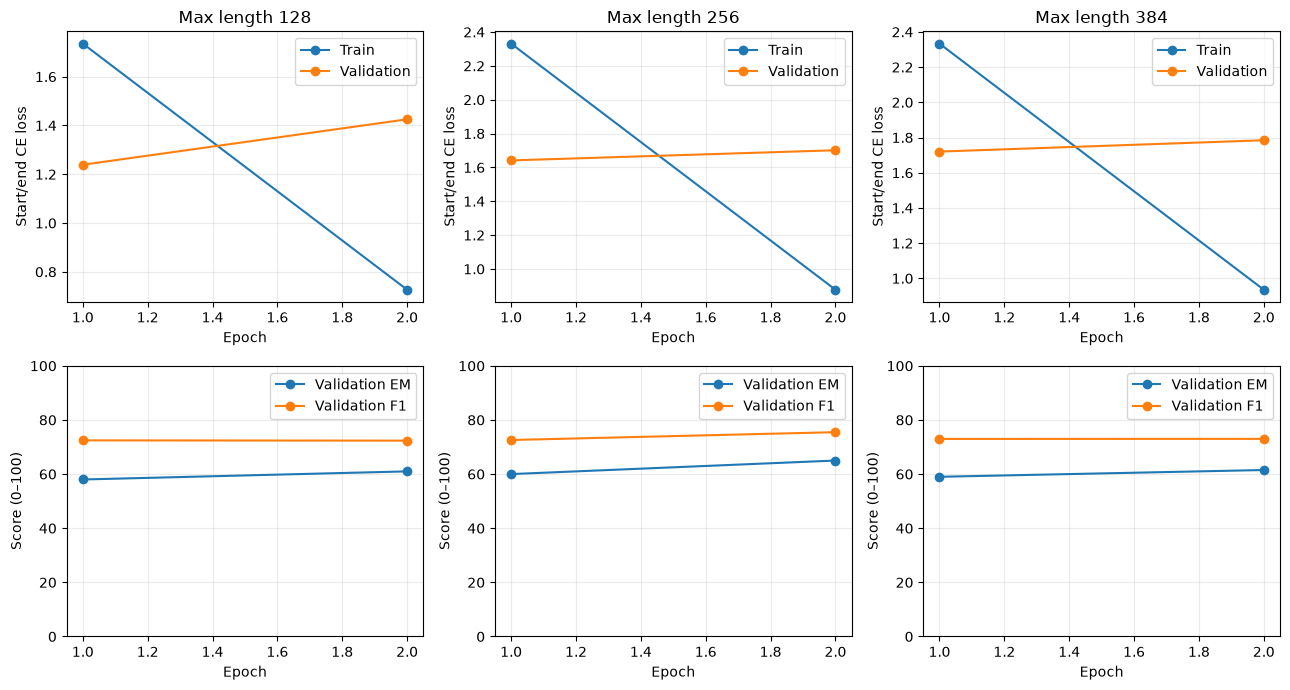

You're using a AlbertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


start logits: (1, 125) end logits: (1, 125)
Gold token positions: 80 81
Prediction: {'text': 'tolerant of religions and explained his policies clearly to all his soldiers', 'start_char': 342, 'end_char': 418, 'score': 13.558366775512695, 'feature_index': 0, 'start_token': 80, 'end_token': 92}
Hardware: {'device': 'cpu', 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'torch': '2.14.1+cpu', 'threads': 4}


In [5]:
fig,axes=plt.subplots(2,3,figsize=(13,7))
for column,(length,r) in enumerate(results.items()):
    history=pd.DataFrame(r['history']);display(history.assign(max_length=length))
    axes[0,column].plot(history.epoch,history.training_loss,'o-',label='Train')
    axes[0,column].plot(history.epoch,history.validation_loss,'o-',label='Validation')
    axes[0,column].set(title=f'Max length {length}',xlabel='Epoch',ylabel='Start/end CE loss')
    axes[1,column].plot(history.epoch,history.em,'o-',label='Validation EM')
    axes[1,column].plot(history.epoch,history.f1,'o-',label='Validation F1')
    axes[1,column].set(xlabel='Epoch',ylabel='Score (0–100)',ylim=(0,100))
    for row in range(2):axes[row,column].legend();axes[row,column].grid(alpha=.25)
fig.tight_layout();fig.savefig(lab_dir/'learning_curves.png',dpi=150);plt.show()
from document_qa import load_document_model,answer_question
model,tokenizer,selected=load_document_model()
demo=splits['test'][0]
f,m=encode_examples([demo],tokenizer,selected)
from qa_model import collate_features
batch=collate_features([f[0]],tokenizer)
with torch.inference_mode():
    output=model(**{k:v.to(DEVICE) for k,v in batch.items()})
print('start logits:',tuple(output.start_logits.shape),'end logits:',tuple(output.end_logits.shape))
print('Gold token positions:',f[0]['start_positions'],f[0]['end_positions'])
print('Prediction:',results[selected]['predictions']['test'][0])
print('Hardware:',results[selected]['hardware'])

**Trả lời:** Với cấu hình được chọn, training loss từ 2.3314 đến 0.8774; validation loss từ 1.6414 đến 1.7015. Loss chấm xác suất start/end, còn F1 chấm span sau decoding, nên hai metric không nhất thiết cùng cải thiện. Loss tính theo windows, EM/F1 tính theo question nên không dùng loss giữa các độ dài như thể cùng một thang độ khó. Decoding xét context tokens, start ≤ end và tối đa 64 subword tokens; lấy candidate tốt nhất giữa các windows.

## 18–20. Exact Match, token F1 và Experiment 3

Manual example: {'em': 0, 'f1': 0.6666666666666666}


,model,em,f1
0,Baseline,7.0,13.327510
1,ALBERT-128,64.5,73.949959
2,ALBERT-256,67.5,79.320205
3,ALBERT-384,69.5,81.657374


,id,question,gold,prediction,em,f1,matched_reference,explanation
0,57273eecf1498d1400e8f520,What was the Genghis Khan's characteristic app...,"[tolerant, tolerant, tolerant of religions]",tolerant of religions and explained his polici...,0,40.000000,tolerant of religions,"Thừa: ['and', 'explained', 'his', 'his', 'poli..."
1,572965566aef051400154e03,What have peridinin-type chloroplasts lost?,[the red algal endosymbiont's original cell me...,original cell membrane,0,66.666667,the red algal endosymbiont's original cell mem...,"Thiếu: ['red', 'algal', 'endosymbionts']"
2,56e17644e3433e1400422f42,What field of computer science analyzes all po...,"[computational complexity theory, computationa...",computability theory,0,40.000000,computational complexity theory,"Thiếu: ['computational', 'complexity']; Thừa: ..."
3,572881022ca10214002da41a,Why did Confucians like the medical field?,[it ensured a high income and medical ethics w...,it ensured a high income,0,50.000000,it ensured a high income and medical ethics we...,"Thiếu: ['and', 'medical', 'ethics', 'were', 'c..."
4,57379ed81c456719005744d9,What can increase the tension force on a load?,"[movable pulleys, connecting the same string m...",By connecting the same string multiple times t...,0,96.969697,connecting the same string multiple times to t...,Thừa: ['by']


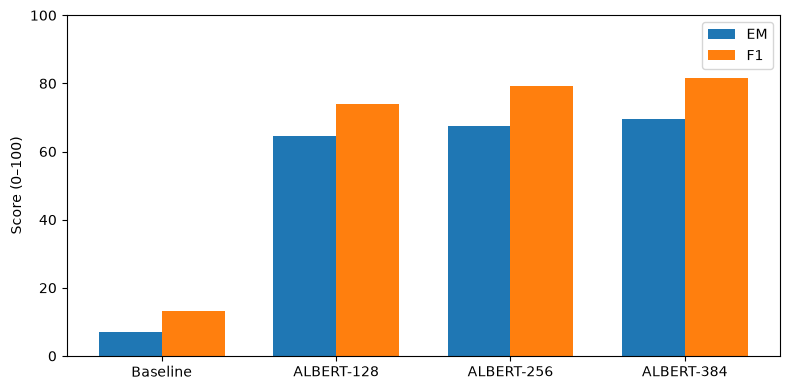

In [6]:
gold=splits['test']
selected_predictions=results[selected]['predictions']['test']
print('Manual example:',score_answer('France','Paris France'))
assert np.isclose(score_answer('France','Paris France')['f1'],2/3)
model_predictions={'Baseline':baseline_predictions['test'],**{f'ALBERT-{length}':r['predictions']['test'] for length,r in results.items()}}
metric_table=pd.DataFrame([dict(model=name,**evaluate_answers(gold,pred)) for name,pred in model_predictions.items()])
display(metric_table)
partial=[]
for row,p in zip(gold,selected_predictions):
    s=example_score(p['text'],row)
    if s['em']==0 and s['f1']>0:
        partial.append(dict(id=row['id'],question=row['question'],gold=[a['text'] for a in row['answers']],
            prediction=p['text'],em=100*s['em'],f1=100*s['f1']))
assert len(partial)>=5
from collections import Counter
for item in partial[:5]:
    ref=max(item['gold'],key=lambda text:score_answer(item['prediction'],text)['f1'])
    missing=list((Counter(normalize_answer(ref).split())-Counter(normalize_answer(item['prediction']).split())).elements())
    extra=list((Counter(normalize_answer(item['prediction']).split())-Counter(normalize_answer(ref).split())).elements())
    item['matched_reference']=ref
    item['explanation']='; '.join(([f'Thiếu: {missing}'] if missing else [])+([f'Thừa: {extra}'] if extra else [])) or 'Cùng word multiset nhưng thứ tự khác'
display(pd.DataFrame(partial[:5]))
x=np.arange(len(metric_table));fig,ax=plt.subplots(figsize=(8,4))
ax.bar(x-.18,metric_table.em,width=.36,label='EM')
ax.bar(x+.18,metric_table.f1,width=.36,label='F1')
ax.set(xticks=x,xticklabels=metric_table.model,ylabel='Score (0–100)',ylim=(0,100))
ax.legend();fig.tight_layout();fig.savefig(lab_dir/'em_f1_analysis.png',dpi=160);plt.show()

**Trả lời:** Model được chọn có test EM = 67.50, F1 = 79.32; baseline có EM = 7.00, F1 = 13.33. Năm ví dụ chỉ ra những normalized words bị thiếu/thừa nên EM = 0 trong khi vẫn có word overlap. F1 dùng multiset words, không dùng ALBERT subwords; lấy max qua các gold references. Các điểm trong bảng dùng thang 0–100.

## 22. Experiment 4 — Question/Context Matching

In [7]:
overlaps=[]
for row in gold:
    q=set(word_terms(row['question']));c=set(word_terms(row['context']))
    overlaps.append(len(q & c)/len(q) if q else 0)
order=sorted(range(len(gold)),key=lambda i:(overlaps[i],gold[i]['id']))
count=max(1,len(order)//4)
lexical_groups={'low_overlap':order[:count],'high_overlap':order[-count:]}
lexical_table=[]
for group,indices in lexical_groups.items():
    for name,pred in [('Baseline',baseline_predictions['test']),('ALBERT',selected_predictions)]:
        lexical_table.append(dict(group=group,model=name,samples=len(indices),mean_overlap=np.mean([overlaps[i] for i in indices]),
            **evaluate_answers([gold[i] for i in indices],[pred[i] for i in indices])))
display(pd.DataFrame(lexical_table))
display(pd.DataFrame([dict(group=group,overlap=overlaps[i],question=gold[i]['question'],
    gold=gold[i]['answers'][0]['text'],prediction=selected_predictions[i]['text'])
    for group,indices in lexical_groups.items() for i in indices[:3]]))

,group,model,samples,mean_overlap,em,f1
0,low_overlap,Baseline,50,0.358193,6.0,6.800000
1,low_overlap,ALBERT,50,0.358193,58.0,73.679487
2,high_overlap,Baseline,50,0.974253,12.0,22.376708
3,high_overlap,ALBERT,50,0.974253,70.0,84.805438


,group,overlap,question,gold,prediction
0,low_overlap,0.000000,Where did these uprisings take place?,southwestern France,southwestern France
1,low_overlap,0.000000,Who discovered this and where did they come from?,Michael Heckenberger and colleagues of the Uni...,Michael Heckenberger and colleagues of the Uni...
2,low_overlap,0.000000,When did Temur rule?,1294 to 1307,1294 to 1307
3,high_overlap,0.857143,Rocks that are a depth where they are ductilel...,metamorphosed,metamorphosed
4,high_overlap,0.857143,How is the opening of the Grainger Market docu...,a painting,painting
5,high_overlap,0.857143,How many phases was the Metro opened in betwee...,five,five


**Trả lời:** ALBERT F1 ở nhóm high overlap là 84.81, nhóm low overlap là 73.68. Mỗi nhóm có 50 questions. Overlap đo tỉ lệ content words của question có mặt trong context; chia theo hai tứ phân vị, không theo prediction. Đây là dấu hiệu về khớp từ, chưa đủ để kết luận model chỉ dựa vào lexical overlap hoặc đã hiểu mọi cách diễn đạt khác nhau. Các lỗi chọn `seven` thay vì `three`, hoặc chọn tỉ số của trận khác trong `error_analysis.md` minh họa việc từ khóa giống nhau vẫn có thể dẫn tới nhầm span, như Prediction 1.

## 23. Experiment 5 — Answer Length

,group,model,samples,em,f1
0,1,Baseline,72,16.666667,16.666667
1,1,ALBERT,72,70.833333,78.172399
2,2–3,Baseline,85,2.352941,14.713572
3,2–3,ALBERT,85,72.941176,82.693263
4,4–6,Baseline,30,0.000000,5.222222
5,4–6,ALBERT,30,56.666667,80.720642
6,7+,Baseline,13,0.000000,4.475524
7,7+,ALBERT,13,38.461538,60.390891


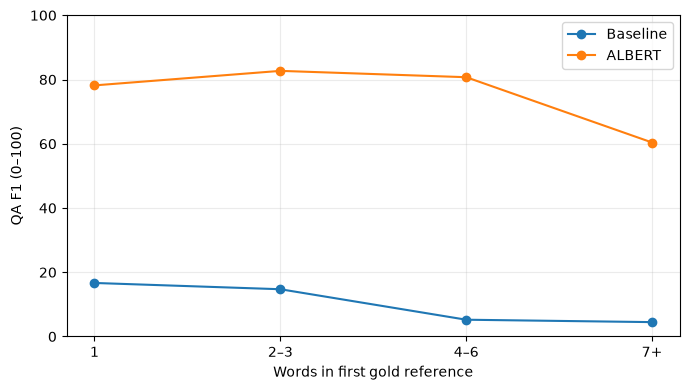

In [8]:
def answer_length_group(row):
    length=len(row['answers'][0]['text'].split())
    return '1' if length==1 else '2–3' if length<=3 else '4–6' if length<=6 else '7+'
length_groups={name:[i for i,row in enumerate(gold) if answer_length_group(row)==name] for name in ['1','2–3','4–6','7+']}
answer_length_table=[]
for group,indices in length_groups.items():
    assert indices
    for name,pred in [('Baseline',baseline_predictions['test']),('ALBERT',selected_predictions)]:
        answer_length_table.append(dict(group=group,model=name,samples=len(indices),
            **evaluate_answers([gold[i] for i in indices],[pred[i] for i in indices])))
answer_length_table=pd.DataFrame(answer_length_table);display(answer_length_table)
fig,ax=plt.subplots(figsize=(7,4))
for name,table in answer_length_table.groupby('model',sort=False):
    ax.plot(table['group'],table.f1,'o-',label=name)
ax.set(xlabel='Words in first gold reference',ylabel='QA F1 (0–100)',ylim=(0,100));ax.legend();ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(lab_dir/'answer_length_analysis.png',dpi=160);plt.show()

**Trả lời:** Nhóm 1 word có EM/F1 = 70.83/78.17; nhóm 7+ có EM/F1 = 38.46/60.39 với 13 mẫu. Nhóm 7+ thấp hơn nhóm 1, phù hợp xu hướng trong Prediction 2, nhưng điểm không giảm đều qua mọi nhóm. Các nhóm không có cùng số mẫu hoặc loại câu hỏi. Độ dài tính theo whitespace words của reference đầu tiên, metric vẫn lấy max qua mọi references. Baseline chỉ xét tối đa 6 word tokens theo regex nên bị hạn chế ở nhóm dài.

## Đối chiếu Prediction 3–4 — Irrelevant context và sentence order

In [9]:
notice='A separate notice describes copper lanterns in a quiet garden. The hallway also contains a wooden bench.'
notice_terms=set(word_terms(notice))
controlled_indices=[i for i,row in enumerate(gold) if not (set(word_terms(row['question'])) & notice_terms)
    and not any(normalize_answer(a['text']) in normalize_answer(notice) for a in row['answers'])][:20]
assert len(controlled_indices)==20
original=[gold[i] for i in controlled_indices]
prefix,suffix=[],[]
for row in original:
    prefix.append(dict(row,context=notice+'\n\n'+row['context'],
        answers=[dict(a,answer_start=a['answer_start']+len(notice)+2) for a in row['answers']]))
    suffix.append(dict(row,context=row['context']+'\n\n'+notice))
for rows in [prefix,suffix]:
    assert all(r['context'][a['answer_start']:a['answer_start']+len(a['text'])]==a['text'] for r in rows for a in r['answers'])
controlled_predictions={'original':[selected_predictions[i] for i in controlled_indices],
    'notice_before':predict_examples(model,prefix,tokenizer,selected),
    'notice_after':predict_examples(model,suffix,tokenizer,selected)}
controlled_rows={'original':original,'notice_before':prefix,'notice_after':suffix}
controlled_table=pd.DataFrame([dict(variant=name,samples=20,**evaluate_answers(controlled_rows[name],p)) for name,p in controlled_predictions.items()])
display(controlled_table)
changed=sum(a['text']!=b['text'] for a,b in zip(controlled_predictions['notice_before'],controlled_predictions['notice_after']))
print('Prediction changed between the two sentence orders:',changed,'/20')
controlled_changes=[dict(question=original[i]['question'],gold=[a['text'] for a in original[i]['answers']],
    original=controlled_predictions['original'][i]['text'],notice_before=a['text'],notice_after=b['text'])
    for i,(a,b) in enumerate(zip(controlled_predictions['notice_before'],controlled_predictions['notice_after'])) if a['text']!=b['text']]
display(pd.DataFrame(controlled_changes))

,variant,samples,em,f1
0,original,20,65.0,79.681818
1,notice_before,20,60.0,70.920290
2,notice_after,20,70.0,79.833333


Prediction changed between the two sentence orders: 2 /20


,question,gold,original,notice_before,notice_after
0,How many tackles did Luke Kuechly register?,"[118, 118, 118]",118,88,118
1,"After the Capital Cities - ABC merger, Frederi...","[president of ABC's broadcasting division, pre...",president of ABC's broadcasting division,president of ABC's broadcasting division; Mich...,president of ABC's broadcasting division


**Trả lời:** F1 của original / notice trước / notice sau lần lượt là 79.68 / 70.92 / 79.83. Đổi thứ tự làm raw answer text thay đổi ở 2/20 cases. Prediction 3 được ủng hộ ở biến thể notice trước, còn notice sau không làm F1 giảm. Có prediction thay đổi khi đổi thứ tự, phù hợp khả năng nêu trong Prediction 4. Gold offsets được cập nhật; context gốc giữ nguyên. Phép thử chỉ gồm 20 cases. Thứ tự có thể thay đổi cả vị trí lẫn cách chia windows, không chỉ Positional Encoding.

## 24–25. Error Analysis — Wrong start và Wrong end

In [10]:
test_features,test_metadata=encode_examples(gold,tokenizer,selected)
def window_contains_gold(meta,row):
    offsets=[off for off in meta['offsets'] if off is not None]
    return bool(offsets) and any(offsets[0][0]<=a['answer_start'] and a['answer_start']+len(a['text'])<=offsets[-1][1] for a in row['answers'])
boundary_records=[]
for i,(row,p) in enumerate(zip(gold,selected_predictions)):
    starts={a['answer_start'] for a in row['answers']}
    ends={a['answer_start']+len(a['text']) for a in row['answers']}
    exact_spans={(a['answer_start'],a['answer_start']+len(a['text'])) for a in row['answers']}
    boundary_records.append(dict(index=i,id=row['id'],wrong_start=p['start_char'] not in starts,
        wrong_end=p['end_char'] not in ends,wrong_span=(p['start_char'],p['end_char']) not in exact_spans,
        **example_score(p['text'],row)))
boundary_table=pd.DataFrame(boundary_records)
print('Raw character boundary counts:',boundary_table[['wrong_start','wrong_end','wrong_span']].sum().to_dict())
error_examples=[];used=set()
for category in ['wrong_start','wrong_end','wrong_span']:
    candidates=[r for r in boundary_records if r[category] and r['em']==0 and r['index'] not in used]
    if category=='wrong_start':candidates.sort(key=lambda r:(r['wrong_end'],-r['f1'],r['index']))
    elif category=='wrong_end':candidates.sort(key=lambda r:(r['wrong_start'],-r['f1'],r['index']))
    else:candidates.sort(key=lambda r:(not (r['wrong_start'] and r['wrong_end']),r['f1'],r['index']))
    assert len(candidates)>=5,category
    for record in candidates[:5]:
        i=record['index'];row=gold[i];p=selected_predictions[i]
        error_examples.append(dict(record,category=category,question=row['question'],context=row['context'],
            answers=row['answers'],prediction=p,
            actual_error=('wrong_start' if record['wrong_start'] else '')+(' + ' if record['wrong_start'] and record['wrong_end'] else '')+('wrong_end' if record['wrong_end'] else '') or 'wrong_span',
            gold_in_any_window=any(window_contains_gold(meta,row) for meta in test_metadata if meta['example_index']==i),
            predicted_window_contains_gold=(window_contains_gold(test_metadata[p['feature_index']],row) if p['feature_index'] is not None else False)))
        used.add(i)
display(pd.DataFrame([dict(category=e['category'],question=e['question'],gold=[a['text'] for a in e['answers']],
    prediction=e['prediction']['text'],actual_error=e['actual_error']) for e in error_examples]))

Raw character boundary counts: {'wrong_start': 48, 'wrong_end': 50, 'wrong_span': 71}


,category,question,gold,prediction,actual_error
0,wrong_start,What can increase the tension force on a load?,"[movable pulleys, connecting the same string m...",By connecting the same string multiple times t...,wrong_start
1,wrong_start,"Besides the V&A's, whose collections are under...","[V&A Museum of Childhood, V&A Museum of Childh...",Museum of Childhood,wrong_start
2,wrong_start,Where was the 1857 riot?,"[Buckland Valley, Buckland Valley near Bright,...",at Buckland Valley,wrong_start
3,wrong_start,How long may the Amazon rainforest be threaten...,"[though the 21st century, though the 21st cent...",21st century,wrong_start
4,wrong_start,Where will the 2009 International Arts Fair be...,"[Sage Gateshead Music and Arts Centre, Sage Ga...",in the Norman Foster designed Sage Gateshead M...,wrong_start
5,wrong_end,What was the Doritos customer Super Bowl ad ca...,"[Crash the Super Bowl, Crash the Super Bowl, C...","Crash the Super Bowl"" contest",wrong_end
6,wrong_end,What was Frensh military presence at start of ...,[no French regular army troops were stationed ...,no French regular army troops were stationed i...,wrong_end
7,wrong_end,"The church states that, as Christians, they ar...","[the way of military action, persons who consc...","military action, nor the way of inaction",wrong_end
8,wrong_end,How much dust is blown out of the Sahara each ...,"[182 million tons, 182 million tons, 182 milli...",182 million,wrong_end
9,wrong_end,What is the name of the stadium in Miami that ...,"[Sun Life Stadium, Sun Life Stadium, Sun Life ...",Sun Life,wrong_end


**Trả lời:** Counts dùng raw character offsets: start/end đúng nếu khớp biên tương ứng của ít nhất một reference, cả span phải khớp cùng một reference. Hai số wrong start và wrong end có thể chồng nhau. Khác normalization của EM, thêm/bớt article hoặc dấu câu vẫn có thể là lệch raw boundary. Phần ví dụ ưu tiên chỉ sai một đầu; cột actual error ghi rõ nếu cả hai cùng sai. Giải thích từng trường hợp nằm trong `error_analysis.md`.

## 26. No-Answer Extension

Không thực hiện mở rộng SQuAD 2.0 trong phần core này. Model SQuAD 1.1 chọn một span trong context, chưa có cơ chế đáng tin cậy để từ chối câu hỏi không có đáp án. Không dùng score logit như xác suất calibrated.

## 27. Application — Document QA

In [11]:
document='A QA model extracts an answer span from the supplied context. A tokenizer maps text to token IDs. Offset mapping connects tokens to character positions. A retriever searches a collection of documents.'
questions=['What does a tokenizer map text to?','What connects tokens to character positions?','What does a retriever search?']
document_outputs=[dict(question=q,**answer_question(q,document,model,tokenizer,selected)) for q in questions]
display(pd.DataFrame(document_outputs))
for p in document_outputs:assert document[p['start_char']:p['end_char']]==p['answer']

,question,answer,start_char,end_char,score
0,What does a tokenizer map text to?,token IDs,87,96,16.952227
1,What connects tokens to character positions?,Offset mapping,98,112,18.122730
2,What does a retriever search?,a collection of documents,174,199,16.397114


## 28. Extractive QA và RAG

Extractive QA nhận sẵn question và context, rồi lấy một đoạn có trong context. RAG có thêm bước tìm tài liệu liên quan từ một collection trước khi đưa context cho bộ trả lời. Lab 10 chưa cần retriever. Nếu đáp án không có trong context, mô hình extractive không thể tự sinh một đáp án mới đúng từ bên ngoài.

## 29–30. AI usage và Reproducibility

AI assistance statement nằm trong `README.md`. Model/tokenizer, splits, seed và cấu hình đã in ở đầu; hardware, history và training time được lưu theo từng cấu hình.

In [12]:
export=[]
export.append(dict(model='Baseline',split='test',max_length=None,**baseline_metrics['test'],
    training_time_sec=baseline_time,train_questions=len(splits['train']),validation_questions=len(splits['validation']),test_questions=len(gold),seed=42))
for length,r in results.items():
    export.append(dict(model='ALBERT',split='test',max_length=length,**r['metrics']['test'],
        validation_em=r['metrics']['validation']['em'],validation_f1=r['metrics']['validation']['f1'],
        training_time_sec=r['training_time_sec'],best_epoch=r['best_epoch'],epochs=CONFIG['epochs'],
        batch_size=CONFIG['batch_size'],learning_rate=CONFIG['learning_rate'],stride=CONFIG['stride'],
        train_questions=len(splits['train']),validation_questions=len(splits['validation']),test_questions=len(gold),seed=42))
result_table=pd.DataFrame(export)
for col in ['max_length','best_epoch','epochs','batch_size','stride','train_questions','validation_questions','test_questions','seed']:
    result_table[col]=result_table[col].astype('Int64')
result_table.to_csv(lab_dir/'results.csv',index=False);display(result_table)
summary=dict(selected_length=selected,length_table=length_table.to_dict('records'),
    metric_table=metric_table.to_dict('records'),partial_examples=partial[:5],
    lexical_table=lexical_table,answer_length_table=answer_length_table.to_dict('records'),
    controlled_table=controlled_table.to_dict('records'),changed_order=changed,controlled_changes=controlled_changes,
    boundary_counts={k:int(v) for k,v in boundary_table[['wrong_start','wrong_end','wrong_span']].sum().to_dict().items()},
    errors=error_examples,document_outputs=document_outputs)
atomic_json(summary,CHECKPOINT_DIR/'analysis_summary.json')

,model,split,max_length,em,f1,training_time_sec,train_questions,validation_questions,test_questions,seed,validation_em,validation_f1,best_epoch,epochs,batch_size,learning_rate,stride
0,Baseline,test,<NA>,7.0,13.327510,0.065390,1000,200,200,42,NaN,NaN,<NA>,<NA>,<NA>,NaN,<NA>
1,ALBERT,test,128,64.5,73.949959,1893.991330,1000,200,200,42,58.0,72.454177,1,2,4,0.00003,32
2,ALBERT,test,256,67.5,79.320205,1285.982776,1000,200,200,42,65.0,75.479077,2,2,4,0.00003,32
3,ALBERT,test,384,69.5,81.657374,1029.386037,1000,200,200,42,61.5,73.009203,2,2,4,0.00003,32


## 33. Individual Learning Check

1. **QA và classification:** QA dự đoán một span từ question/context; classification dự đoán một nhãn cho sequence.
2. **Start/end:** Cần cả hai biên để biết đáp án bắt đầu ở đâu và dài đến đâu.
3. **Character/token:** Character index đếm ký tự gốc, token index đếm vị trí sau tokenizer.
4. **Offset mapping:** Nối hai hệ tọa độ để gán target và lấy lại answer text.
5. **Stride:** Tạo phần overlap giữa các windows.
6. **Context dài:** Model có giới hạn input; sliding windows cho phép xử lý phần vượt giới hạn.
7. **EM:** Đo prediction khớp hoàn toàn gold sau normalization.
8. **F1 và accuracy:** QA F1 đo word overlap của từng answer, không phải tỉ lệ nhãn token đúng như token accuracy.
9. **F1 > 0, EM = 0:** Answer còn một phần từ trùng nhưng chưa khớp hoàn toàn.
10. **Wrong start/end:** Sai biên đầu so với sai biên cuối; một prediction có thể sai cả hai.
11. **QA và RAG:** QA nhận context có sẵn; RAG thêm retrieval rồi mới trả lời dựa trên tài liệu.
12. **Không trả lời được:** Khi thông tin cần thiết không nằm trong context hoặc đáp án không thể biểu diễn bằng một span liên tục.

## 34–36. Reflection và Bridge

Reflection 300–500 từ nằm trong `reflection.md`. Lab 08 dùng sequence head, Lab 09 dùng token head, Lab 10 dùng start/end head. Lab 11 bổ sung retrieval khi chưa biết document phù hợp; Lab 12 kết hợp retrieval với generation.